# YZ50 Hafta 10: GPT-2 (124M)

Hafta 8'deki GPT'yi GPT-2 ölçeğine taşıyıp Hugging Face ağırlıklarını kendi modelime yüklüyorum. Sonra modeli konuşturuyorum ve eğitime başlamadan önceki kontrolleri yapıyorum. Kaynak: Karpathy, *Let's reproduce GPT-2 (124M)*, videonun 0:03:39 – 1:02:00 aralığı.

## Kurulum ve ayarlar

In [1]:
%pip install -q transformers tiktoken matplotlib pandas numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\Users\mehme\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
import math
import time
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import tiktoken
from IPython.display import display
from transformers import GPT2LMHeadModel

SEED = 1337
MODEL_TIPI = "gpt2"
METIN_YOLU = "../hafta7/input.txt"
URETIM_SAYISI = 5
URETIM_UZUNLUK = 40
TOP_K = 50
BATCH_B = 4
BATCH_T = 32
OGRENME_ORANI = 3e-4
EZBER_ADIM = 300

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(SEED)
if device == "cuda":
    torch.cuda.manual_seed(SEED)

enc = tiktoken.get_encoding("gpt2")
enc_gpt4 = tiktoken.get_encoding("cl100k_base")

print(f"PyTorch {torch.__version__}  |  cihaz: {device}" + (f" ({torch.cuda.get_device_name(0)})" if device == "cuda" else ""))
print(f"GPT-2 tokenizer vocab boyutu: {enc.n_vocab}")
if device == "cpu":
    print("Uyarı: GPU bulunamadı. Bu notebook CPU'da da çalışır ama Görev 4 yavaş olur.")

C:\Users\mehme\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch 2.13.0+cpu  |  cihaz: cpu
GPT-2 tokenizer vocab boyutu: 50257
Uyarı: GPU bulunamadı. Bu notebook CPU'da da çalışır ama Görev 4 yavaş olur.


## Görev 1: Hazır GPT-2'yi incele *(Video 0:03:39 – 0:13:47)*

Hugging Face'ten GPT-2 (124M) ağırlıklarını yükle. Her ağırlığın adını ve boyutunu yazdır, toplam parametre sayısını hesapla. Pozisyon embedding'lerini (`wpe`) çiz ve ne gördüğünü yaz.

In [3]:
hf_model = GPT2LMHeadModel.from_pretrained(MODEL_TIPI)
hf_state = hf_model.state_dict()

def nokta(n):
    return f"{n:,}".replace(",", ".")

tablo1 = pd.DataFrame(
    [(ad, str(tuple(t.shape)), nokta(t.numel())) for ad, t in hf_state.items()],
    columns=["Ağırlık adı", "Boyut", "Eleman sayısı"],
)
print(f"state_dict içindeki anahtar sayısı: {len(tablo1)}")
pd.set_option("display.max_rows", None)
display(tablo1.style.hide(axis="index"))

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 294.89it/s]


state_dict içindeki anahtar sayısı: 149


Ağırlık adı,Boyut,Eleman sayısı
transformer.wte.weight,"(50257, 768)",38.597.376
transformer.wpe.weight,"(1024, 768)",786.432
transformer.h.0.ln_1.weight,"(768,)",768
transformer.h.0.ln_1.bias,"(768,)",768
transformer.h.0.attn.c_attn.weight,"(768, 2304)",1.769.472
transformer.h.0.attn.c_attn.bias,"(2304,)",2.304
transformer.h.0.attn.c_proj.weight,"(768, 768)",589.824
transformer.h.0.attn.c_proj.bias,"(768,)",768
transformer.h.0.ln_2.weight,"(768,)",768
transformer.h.0.ln_2.bias,"(768,)",768


In [4]:
cfg_hf = hf_model.config
D, V, P, L = cfg_hf.n_embd, cfg_hf.vocab_size, cfg_hf.n_positions, cfg_hf.n_layer

blok_ogeleri = pd.DataFrame(
    [
        ("ln_1 (ağırlık + bias)", 2 * D),
        ("attn.c_attn", D * 3 * D + 3 * D),
        ("attn.c_proj", D * D + D),
        ("ln_2 (ağırlık + bias)", 2 * D),
        ("mlp.c_fc", D * 4 * D + 4 * D),
        ("mlp.c_proj", 4 * D * D + D),
    ],
    columns=["Bir bloktaki parça", "Parametre"],
)
bir_blok = int(blok_ogeleri["Parametre"].sum())
elle_toplam = V * D + P * D + L * bir_blok + 2 * D

toplam_parametre = sum(p.numel() for p in hf_model.parameters())
state_toplam = sum(t.numel() for t in hf_state.values())

blok_goster = blok_ogeleri.copy()
blok_goster["Parametre"] = blok_goster["Parametre"].map(nokta)
display(blok_goster.style.hide(axis="index"))

ozet = pd.DataFrame(
    [
        ("Bir blok", nokta(bir_blok)),
        ("12 blok", nokta(L * bir_blok)),
        ("wte (token embedding)", nokta(V * D)),
        ("wpe (pozisyon embedding)", nokta(P * D)),
        ("ln_f", nokta(2 * D)),
        ("Elle hesaplanan toplam", nokta(elle_toplam)),
        ("Modelin parameters() toplamı", nokta(toplam_parametre)),
        ("state_dict() elemanlarının toplamı", nokta(state_toplam)),
    ],
    columns=["Kalem", "Değer"],
)
display(ozet.style.hide(axis="index"))

assert elle_toplam == toplam_parametre
print(f"\nElle hesapla ile modelin sayısı aynı: {nokta(toplam_parametre)}")
print(f"state_dict toplamı {nokta(state_toplam - toplam_parametre)} fazla: lm_head.weight ile wte aynı tensör, iki kez sayılıyor.")

Bir bloktaki parça,Parametre
ln_1 (ağırlık + bias),1.536
attn.c_attn,1.771.776
attn.c_proj,590.592
ln_2 (ağırlık + bias),1.536
mlp.c_fc,2.362.368
mlp.c_proj,2.360.064


Kalem,Değer
Bir blok,7.087.872
12 blok,85.054.464
wte (token embedding),38.597.376
wpe (pozisyon embedding),786.432
ln_f,1.536
Elle hesaplanan toplam,124.439.808
Modelin parameters() toplamı,124.439.808
state_dict() elemanlarının toplamı,163.037.184



Elle hesapla ile modelin sayısı aynı: 124.439.808
state_dict toplamı 38.597.376 fazla: lm_head.weight ile wte aynı tensör, iki kez sayılıyor.


**Ağırlıklar:** `wte` 50257 × 768 (token embedding), `wpe` 1024 × 768 (pozisyon embedding), 12 blok (`h.0` ... `h.11`). Her blokta `ln_1`, `attn.c_attn` (768 × 2304, yani q, k, v tek katmanda), `attn.c_proj`, `ln_2`, `mlp.c_fc` (768 × 3072) ve `mlp.c_proj` (3072 × 768) var. Sonda `ln_f` ve `lm_head`.

**Cevap: Toplam parametre sayısı**

GPT-2 (124M) toplam **124.439.808** parametreli. Bir bloğun parametrelerini elle toplayıp 12 ile çarptım, üstüne `wte`, `wpe` ve `ln_f`'yi ekledim. Modelin `parameters()` toplamıyla aynı çıktı.

`state_dict()` elemanlarını toplayınca 38.597.376 fazla çıkıyor, yani `wte` kadar. Sebebi şu: GPT-2 giriş embedding'i (`wte`) ile çıkış katmanını (`lm_head`) paylaşıyor, ikisi aynı tensör. `parameters()` bir kez sayıyor, `state_dict()` iki ismi de listeliyor.

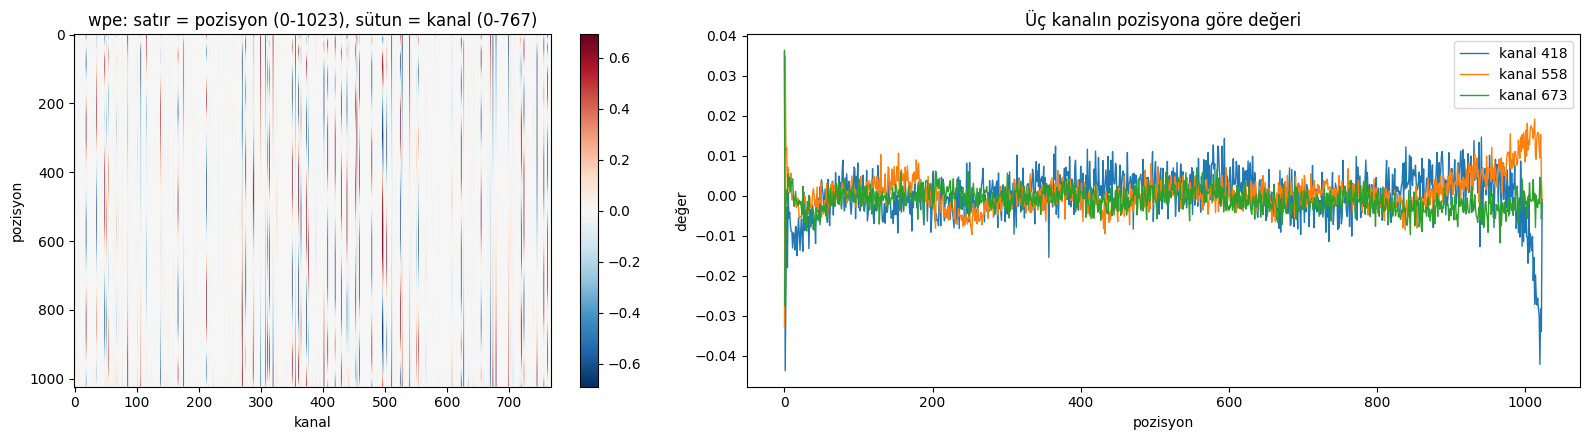

In [5]:
wpe = hf_state["transformer.wpe.weight"].detach().cpu().numpy()
rng = np.random.default_rng(SEED)
kanallar = sorted(rng.choice(wpe.shape[1], 3, replace=False).tolist())
sinir = float(np.percentile(np.abs(wpe), 99))

fig, eksenler = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [1, 1.4]})
im = eksenler[0].imshow(wpe, aspect="auto", cmap="RdBu_r", vmin=-sinir, vmax=sinir)
eksenler[0].set_title("wpe: satır = pozisyon (0-1023), sütun = kanal (0-767)")
eksenler[0].set_xlabel("kanal")
eksenler[0].set_ylabel("pozisyon")
fig.colorbar(im, ax=eksenler[0])

for k in kanallar:
    eksenler[1].plot(wpe[:, k], label=f"kanal {k}", linewidth=1)
eksenler[1].set_title("Üç kanalın pozisyona göre değeri")
eksenler[1].set_xlabel("pozisyon")
eksenler[1].set_ylabel("değer")
eksenler[1].legend()
plt.tight_layout()
plt.show()

**Cevap: Pozisyon embedding'inde ne görüyorum?**

`wpe`'nin her satırı bir pozisyonun vektörü, model bir token'ın kaçıncı sırada olduğunu buradan okuyor. Orijinal Transformer makalesinde bunlar sabit sinüs ve kosinüs dalgalarıydı, GPT-2'de ise sıradan parametreler: rastgele başlıyor, yapıyı eğitim buluyor.

- Isı haritasında tablonun büyük kısmı soluk, yani değerler sıfıra yakın. Dikey çizgiler var: bir avuç kanal çok büyük değerler (yaklaşık ±0.6) alıyor ve bu değerler pozisyon boyunca çok değişmiyor. Yani tablonun büyük kısmını pozisyona göre değişen bir desen değil, kanaldan kanala değişen sabit bir seviye belirliyor.
- Rastgele seçtiğim üç kanalı pozisyona göre çizince değerler çoğu yerde ±0.01 içinde ve tırtıklı, pürüzsüz bir dalga değil. Karpathy videoda sinüse benzeyen kanallar gösteriyor, benim rastgele seçtiğim üç kanalda bu pek belli olmuyor. Sadece üç kanala baktım, diğerleri farklı olabilir.
- Pozisyon 0 belirgin şekilde farklı: üç kanalda da değerler yaklaşık ±0.03–0.04'e fırlıyor, ortadaki değerlerin birkaç katı. İlk token'ın özel bir yeri var gibi.
- Uçlarda kanallar kayıyor: kanal 558 yaklaşık 850'den sonra yukarı çıkıyor, kanal 418 900 civarında yükselip en sonda (1000'in ötesinde) hızla aşağı düşüyor. Orta kısım (yaklaşık 200–800) sıfır etrafında gürültülü.
- Karpathy tırtıklılığı modelin tam eğitilmemesine yoruyor. Daha çok eğitilseydi eğriler daha düzgün olurdu diyor.


## Görev 2: GPT-2'yi kendin yaz ve ağırlıkları yükle *(Video 0:13:47 – 0:31:00)*

Hafta 8'deki GPT'den yola çıkıp GPT-2 modülünü yaz. Hugging Face ağırlıklarını kendi modeline yükle. Aynı girdi için kendi modelinin logits'inin Hugging Face modelininkiyle aynı çıktığını göster. Hafta 8'deki GPT'den farklarını madde madde yaz. Bazı ağırlıkları yüklerken neden transpoze etmek gerektiğini yaz.

Kendi modelimin parametre adlarını Hugging Face'inkilerle birebir aynı verdim (`transformer.wte`, `transformer.h.0.attn.c_attn` gibi), böylece ağırlıklar isimle tek tek kopyalanıyor.

In [6]:
@dataclass
class GPTConfig:
    block_size: int = 1024
    vocab_size: int = 50257
    n_layer: int = 12
    n_head: int = 12
    n_embd: int = 768


class CausalSelfAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd)
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        self.n_head = config.n_head
        self.n_embd = config.n_embd
        maske = torch.tril(torch.ones(config.block_size, config.block_size))
        self.register_buffer("maske", maske.view(1, 1, config.block_size, config.block_size), persistent=False)

    def forward(self, x):
        B, T, C = x.size()
        q, k, v = self.c_attn(x).split(self.n_embd, dim=2)
        q = q.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        k = k.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        v = v.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        att = (q @ k.transpose(-2, -1)) * (k.size(-1) ** -0.5)
        att = att.masked_fill(self.maske[:, :, :T, :T] == 0, float("-inf"))
        att = F.softmax(att, dim=-1)
        y = att @ v
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.c_proj(y)


class MLP(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4 * config.n_embd)
        self.gelu = nn.GELU(approximate="tanh")
        self.c_proj = nn.Linear(4 * config.n_embd, config.n_embd)

    def forward(self, x):
        return self.c_proj(self.gelu(self.c_fc(x)))


class Block(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self, x):
        x = x + self.attn(self.ln_1(x))
        x = x + self.mlp(self.ln_2(x))
        return x


class GPT(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config
        self.transformer = nn.ModuleDict(dict(
            wte=nn.Embedding(config.vocab_size, config.n_embd),
            wpe=nn.Embedding(config.block_size, config.n_embd),
            h=nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f=nn.LayerNorm(config.n_embd),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)

    def forward(self, idx, targets=None):
        B, T = idx.size()
        assert T <= self.config.block_size, f"Dizi uzunluğu {T}, block_size {self.config.block_size} değerini aşıyor"
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)
        x = self.transformer.wte(idx) + self.transformer.wpe(pos)
        for blok in self.transformer.h:
            x = blok(x)
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

In [7]:
TRANSPOZ = ("attn.c_attn.weight", "attn.c_proj.weight", "mlp.c_fc.weight", "mlp.c_proj.weight")


def agirliklari_yukle(model, hf_state, transpoz_edilmeyen=()):
    hf_anahtarlar = [k for k in hf_state if not k.endswith((".attn.bias", ".attn.masked_bias"))]
    state = model.state_dict()
    assert sorted(hf_anahtarlar) == sorted(state.keys()), "Anahtar adları eşleşmiyor"
    with torch.no_grad():
        for k in hf_anahtarlar:
            kaynak = hf_state[k]
            if k.endswith(TRANSPOZ) and not k.endswith(tuple(transpoz_edilmeyen)):
                assert kaynak.shape[::-1] == state[k].shape, f"{k}: transpoz sonrası şekil uymuyor"
                state[k].copy_(kaynak.t())
            else:
                assert kaynak.shape == state[k].shape, f"{k}: şekil uymuyor"
                state[k].copy_(kaynak)
    return model


model = agirliklari_yukle(GPT(GPTConfig()), hf_state)
model_parametre = sum(p.numel() for p in model.parameters())
print(f"Yüklenen anahtar sayısı: {len(model.state_dict())}")
print(f"Kendi modelimizin parametre sayısı: {nokta(model_parametre)}  (lm_head ayrı olduğu için wte kadar fazla)")

Yüklenen anahtar sayısı: 149
Kendi modelimizin parametre sayısı: 163.037.184  (lm_head ayrı olduğu için wte kadar fazla)


`lm_head` ile `wte`'yi bu hafta paylaştırmadım, paylaşım gelecek haftanın konusu. Bu yüzden kendi modelim 124M'den `wte` kadar fazla çıkıyor (163.037.184). Hugging Face'te ikisi aynı tensör olduğu için yüklemede iki tabloya da aynı değerler gidiyor, modelin çıktısı değişmiyor.

**Cevap: Bazı ağırlıkları yüklerken neden transpoze etmek gerekiyor?**

Hugging Face'in GPT-2'si OpenAI'ın TensorFlow kodundan geliyor. O kodda `c_attn`, `c_proj` ve `c_fc` katmanları `Conv1D` olarak yazılmış. `Conv1D` ağırlığı **(giriş, çıkış)** şeklinde saklıyor ve `x @ W` hesaplıyor. PyTorch'un `nn.Linear` katmanı ise **(çıkış, giriş)** şeklinde saklıyor ve `x @ W.T` hesaplıyor. Sayılar aynı, dizilişleri ters. Bu yüzden dört ağırlığı transpoze ederek kopyalıyorum: `attn.c_attn.weight`, `attn.c_proj.weight`, `mlp.c_fc.weight`, `mlp.c_proj.weight`.

Tuzak: `attn.c_proj` 768 × 768, yani kare. Transpoze etmeyi unutursam şekil hatası gelmiyor, kod sessizce çalışıp yanlış sonuç veriyor. Aşağıda bunu da denedim.

In [8]:
hatali_model = agirliklari_yukle(GPT(GPTConfig()), hf_state, transpoz_edilmeyen=("attn.c_proj.weight",))

model = model.to(device).eval()
hatali_model = hatali_model.to(device).eval()
hf_model = hf_model.to(device).eval()

girdiler = {
    "Gerçek cümle": torch.tensor([enc.encode("Hello, I'm a language model,")], device=device),
    "Rastgele token'lar": torch.randint(0, cfg_hf.vocab_size, (2, 24), device=device, generator=torch.Generator(device=device).manual_seed(SEED)),
}

satirlar = []
with torch.no_grad():
    for ad, girdi in girdiler.items():
        hf_logits = hf_model(girdi).logits
        kendi_logits, _ = model(girdi)
        hatali_logits, _ = hatali_model(girdi)
        satirlar.append((
            ad,
            str(tuple(kendi_logits.shape)),
            f"{(kendi_logits - hf_logits).abs().max().item():.2e}",
            bool(torch.allclose(kendi_logits, hf_logits, rtol=1e-3, atol=1e-3)),
            f"%{(kendi_logits.argmax(-1) == hf_logits.argmax(-1)).float().mean().item() * 100:.0f}",
            f"{(hatali_logits - hf_logits).abs().max().item():.2f}",
            bool(torch.allclose(hatali_logits, hf_logits, rtol=1e-3, atol=1e-3)),
            f"%{(hatali_logits.argmax(-1) == hf_logits.argmax(-1)).float().mean().item() * 100:.0f}",
        ))

display(pd.DataFrame(satirlar, columns=[
    "Girdi", "Logits şekli", "En büyük fark (kendi modelim)", "allclose (1e-3)", "Aynı en olası token",
    "En büyük fark (c_proj transpozsuz)", "allclose (1e-3)", "Aynı en olası token",
]).style.hide(axis="index"))

Girdi,Logits şekli,En büyük fark (kendi modelim),allclose (1e-3),Aynı en olası token,En büyük fark (c_proj transpozsuz),allclose (1e-3),Aynı en olası token
Gerçek cümle,"(1, 8, 50257)",4.58e-05,True,%100,161.68,False,%12
Rastgele token'lar,"(2, 24, 50257)",6.10e-05,True,%100,105.51,False,%4


Kendi modelimin logits'i Hugging Face ile aynı çıktı. En büyük fark gerçek cümlede 4.58e-05, rastgele token'larda 6.10e-05, yani yuvarlama hatası kadar. `allclose` iki girdide de True ve her pozisyonda en olası token %100 aynı. `attn.c_proj`'u transpoze etmeden yüklediğim modelde kod hatasız çalıştı ama en büyük fark 161.68 ve 105.51'e çıktı, en olası token'lar sadece %12 ve %4 oranında tutuyor. Yüklemenin doğru olduğunu "kod çalıştı" diye değil, bu karşılaştırmayla anlıyorum.

**Cevap: Hafta 8'deki GPT'den farklar**

- **Ölçek:** Hafta 8'de 256 boyut, 4 blok, 4 head, 128 bağlam ve harf düzeyinde 65 token vardı. GPT-2'de 768 boyut, 12 blok, 12 head, 1024 bağlam ve 50.257 token var. Bir head'in boyutu ikisinde de 64.
- **q, k, v tek katmanda:** Hafta 8'de her head'in ayrı `key`, `query`, `value` katmanı vardı. GPT-2'de tek bir `c_attn` katmanı 768'i 2304'e çıkarıyor, sonuç üçe bölünüyor.
- **Head'ler tek seferde:** Hafta 8'de head'ler ayrı modüllerdi ve çıktıları `torch.cat` ile birleştiriliyordu. GPT-2 kodunda head sayısı batch gibi ek bir eksen, 12 head tek matris çarpımında hesaplanıyor.
- **Aktivasyon:** Hafta 8'de ReLU, GPT-2'de GELU (tanh yaklaşımıyla). ReLU negatif tarafta tam sıfır ve gradyan da sıfır, GELU yumuşak olduğu için orada da küçük bir gradyan bırakıyor.
- **Bias:** Hafta 8'de key, query, value `bias=False` idi. GPT-2'de `c_attn` bias'lı. `lm_head` ise bias'sız.
- **Çıkış katmanı:** GPT-2'de `lm_head` ile `wte` aynı ağırlığı paylaşıyor.
- **Katman türü:** Hugging Face'te `c_attn`, `c_proj`, `c_fc` `Conv1D`, bu yüzden dört ağırlık transpoze ediliyor.
- **Aynı kalanlar:** LayerNorm'un önce gelmesi (pre-norm), residual bağlantılar, nedensel maske, softmax, token ve pozisyon embedding'lerinin toplanması ve çıkıştan önceki son LayerNorm.

In [9]:
del hatali_model, hf_model, hf_state
if device == "cuda":
    torch.cuda.empty_cache()

## Görev 3: Modeli konuştur *(Video 0:31:00 – 0:45:50)*

Sampling döngüsünü yaz, top-k ile örnek üret. Önce İngilizce bir başlangıç cümlesi dene, sonra Türkçe bir cümle. GPT-2'nin Türkçe çıktısı neden kötü? Aynı Türkçe cümle GPT-2'nin tokenizer'ında kaç token tutuyor? Geçen haftaki sonuçlarınla bağla.

Döngüde her turda son pozisyonun logits'ini alıp softmax'a sokuyorum, en olası 50 token'ı tutup (top-k) onlardan olasılıklarıyla orantılı bir tane çekiyorum ve diziye ekleyip başa dönüyorum.

In [10]:
@torch.no_grad()
def uret(model, idx, max_yeni, top_k=50, generator=None):
    model.eval()
    for _ in range(max_yeni):
        idx_cond = idx[:, -model.config.block_size:]
        logits, _ = model(idx_cond)
        olasilik = F.softmax(logits[:, -1, :], dim=-1)
        top_olasilik, top_indeks = torch.topk(olasilik, top_k, dim=-1)
        secilen = torch.multinomial(top_olasilik, num_samples=1, generator=generator)
        yeni_token = torch.gather(top_indeks, -1, secilen)
        idx = torch.cat((idx, yeni_token), dim=1)
    return idx


def ornek_uret(baslangic, adet=URETIM_SAYISI, uzunluk=URETIM_UZUNLUK, top_k=TOP_K):
    idx = torch.tensor(enc.encode(baslangic), dtype=torch.long, device=device).unsqueeze(0).repeat(adet, 1)
    g = torch.Generator(device=device)
    g.manual_seed(SEED)
    cikti = uret(model, idx, uzunluk, top_k, g)
    print(f"Başlangıç: {baslangic!r}  ({idx.size(1)} token)  |  top_k={top_k}  |  {adet} örnek, her biri {uzunluk} yeni token\n")
    for i in range(adet):
        print(f"[{i + 1}] {enc.decode(cikti[i].tolist())}\n")

In [11]:
ornek_uret("Hello, I'm a language model,")

Başlangıç: "Hello, I'm a language model,"  (8 token)  |  top_k=50  |  5 örnek, her biri 40 yeni token

[1] Hello, I'm a language model, which I used before for all my courses at my university. I'm a young programmer. I'm going to write a program that generates a new string at compile time. That way, you're not

[2] Hello, I'm a language model, not a computer science or technical system. I wrote this book so I would like that you can follow along because I just do. Thanks for reading my description of the various languages and what I did.

[3] Hello, I'm a language model, too - as an intern, that's how you speak a given language. You're not writing a language model. What you're writing is the program you write. As you build new programs, they

[4] Hello, I'm a language model, I'm a language, I'm a language,

and I think I'm probably right.

Karen: You used to call words like "gather" to describe things?


[5] Hello, I'm a language model, and the thing about language models is they don't

In [12]:
ornek_uret("Merhaba, ben bir dil modeliyim,")

Başlangıç: 'Merhaba, ben bir dil modeliyim,'  (11 token)  |  top_k=50  |  5 örnek, her biri 40 yeni token

[1] Merhaba, ben bir dil modeliyim, hakol. The second is of Baha'u'llah, one of His disciples, who had a vision of them on the mountain, a vision which became clear to him. What follows

[2] Merhaba, ben bir dil modeliyim, ben gesya-daik, ben baik-daziyim kalayim, ajdeen azadebi, havad-yeh. Yiliye

[3] Merhaba, ben bir dil modeliyim, iyah ghan al-albikalil haka' haba' al-iyyam al-alba-mahmadah ibn imran az-sadiq ibn '

[4] Merhaba, ben bir dil modeliyim, imayim, al-manas wa shaa-hara, wa alal em-ma'iyya, al-manas siyya, al-menas wa manas

[5] Merhaba, ben bir dil modeliyim, ha'un a'i ngayen vakhiye ngayen, ve'esir vakhiye vakhiye, tashii ma'i ha'un a



In [13]:
def parca(b):
    try:
        return repr(b.decode("utf-8"))
    except UnicodeDecodeError:
        return "".join(f"\\x{x:02x}" for x in b)


cumleler = {
    "Türkçe": "İstanbul'da ışıklı ağaçların gölgesinde çocuklar güzel şarkılar söyledi.",
    "İngilizce": "In Istanbul, children sang beautiful songs in the shade of the illuminated trees.",
}

satirlar = []
for dil, cumle in cumleler.items():
    kelime = len(cumle.split())
    t2 = len(enc.encode(cumle))
    t4 = len(enc_gpt4.encode(cumle))
    satirlar.append((dil, len(cumle), len(cumle.encode("utf-8")), kelime, t2, f"{t2 / kelime:.2f}", t4, f"{t4 / kelime:.2f}"))

tablo3 = pd.DataFrame(satirlar, columns=["Dil", "Karakter", "Byte", "Kelime", "Token (GPT-2)", "Token/kelime (GPT-2)", "Token (GPT-4)", "Token/kelime (GPT-4)"])
display(tablo3.style.hide(axis="index"))

tr_gpt2, en_gpt2 = satirlar[0][4], satirlar[1][4]
tr_gpt4, en_gpt4 = satirlar[0][6], satirlar[1][6]
print(f"\nTürkçe cümle İngilizce karşılığından GPT-2'de {tr_gpt2 / en_gpt2:.2f} kat, GPT-4'te {tr_gpt4 / en_gpt4:.2f} kat fazla token tutuyor.")

tr_token = [parca(enc.decode_single_token_bytes(t)) for t in enc.encode(cumleler["Türkçe"])]
print("\nTürkçe cümlenin GPT-2 token'ları:")
print("  ".join(tr_token))

Dil,Karakter,Byte,Kelime,Token (GPT-2),Token/kelime (GPT-2),Token (GPT-4),Token/kelime (GPT-4)
Türkçe,72,86,8,43,5.38,31,3.88
İngilizce,81,81,13,15,1.15,15,1.15



Türkçe cümle İngilizce karşılığından GPT-2'de 2.87 kat, GPT-4'te 2.07 kat fazla token tutuyor.

Türkçe cümlenin GPT-2 token'ları:
\xc4  \xb0  'stanbul'  "'d"  'a'  ' '  'ı'  'ş'  'ı'  'kl'  'ı'  ' a'  'ğ'  'a'  'ç'  'lar'  'ı'  'n'  ' g'  'ö'  'l'  'ges'  'ind'  'e'  \x20\xc3  \xa7  'oc'  'uk'  'lar'  ' g'  'ü'  'zel'  \x20\xc5  \x9f  'ark'  'ı'  'lar'  ' s'  'ö'  'y'  'led'  'i'  '.'


**Çıktılarda ne gördüm?**

İngilizce başlangıçla beş örnek de dilbilgisi olarak düzgün cümleler. Ama anlam kayıyor: biri bir programlama kitabına, biri "intern" konuşmasına kayıyor, dördüncüde "I'm a language," kendini tekrar ediyor. 124M model uzun vadeli plan yapmıyor, her token'da tek bir seçim yapıyor.

Türkçe başlangıçta ("Merhaba, ben bir dil modeliyim,") model Türkçe devam etmedi. Beş örnekten biri İngilizceye geçti ("hakol. The second is of Baha'u'llah, one of His disciples..."). Kalan dördü İngilizce de değil: Arapça ya da Farsça'nın Latin harfle yazılmışına benzeyen anlamsız diziler ("al-manas wa shaa-hara", "vakhiye vakhiye"). Arada "ben" ve "ve" gibi Türkçe parçalar çıkıyor ama cümle kurulmuyor. Bunu şöyle yorumluyorum: "Merhaba" gibi kelimeler token'lara bölününce modelin gördüğü en yakın metinler İngilizce sayfalarda geçen Arapça/Farsça transliterasyonlar olabilir. Bunu ölçmedim, tahmin.

**Cevap: GPT-2'nin Türkçe çıktısı neden kötü?**

Birkaç sebep birleşiyor. Hangisinin ne kadar etkili olduğunu ölçmedim, hepsi muhtemel sebepler.

1. **Eğitim verisi.** GPT-2 makalesine göre OpenAI, eğitim verisi WebText'ten İngilizce olmayan sayfaları bilerek çıkarmış. Makale, bir dil dedektörüyle veride yalnızca yaklaşık 10 MB Fransızca bulunduğunu söylüyor. Model Türkçeyi neredeyse hiç görmemiş olmalı. Çıktının Türkçe yerine İngilizceye ya da anlamsız diziye kayması da bununla uyumlu.
2. **Tokenizer.** Sözlük ağırlıklı olarak İngilizce metinden kurulduğu için Türkçe kelimeler ve ekler hazır parça değil. Çıktıdaki listede 43 token'ın çoğu 1–2 harflik parça, `İ`, `ç`, `ş` harfleri ise byte parçalarına bölünmüş (`\xc4 \xb0`, `\xc3 \xa7`, `\xc5 \x9f`).
3. **Bağlam.** Aynı anlam daha çok token tutunca 1024 token'lık pencerede daha az içerik kalıyor.
4. **Model küçük.** 124M parametre İngilizcede bile sınırlı, az gördüğü bir dilde daha da zayıf.

**Cevap: Aynı Türkçe cümle GPT-2'nin tokenizer'ında kaç token tutuyor, geçen haftayla bağı ne?**

"İstanbul'da ışıklı ağaçların gölgesinde çocuklar güzel şarkılar söyledi." cümlesi GPT-2'de **43 token** tutuyor. İngilizce karşılığı ("In Istanbul, children sang beautiful songs in the shade of the illuminated trees.") **15 token**. Yani **2.87 kat**. Kelime başına düşen token Türkçede 5.38, İngilizcede 1.15. Karakter sayısı ikisinde de benzer (72 ve 81), fark anlamdan değil sözlükten geliyor.

Aynı cümle GPT-4'ün tokenizer'ında (cl100k_base) 31 token, İngilizcesi 15, oran **2.07**. Hafta 9'da GPT-4 tokenizer'ında aynı paragraf için Türkçe/İngilizce oranı 1.92 çıkmıştı. Tek cümle olduğu için sayı biraz farklı ama yön aynı: Türkçe her durumda daha çok token tutuyor. GPT-4'ün sözlüğü daha büyük (yaklaşık 100 bin) ve oran 2.87'den 2.07'ye düşüyor, GPT-2'nin 50.257'lik sözlüğü Türkçede daha kötü. Sebep eklemeli dil: bir kelime kök ve eklerle uzuyor, İngilizce ağırlıklı sözlükte bu ekler hazır parça değil. Hafta 9'da kendi tokenizer'ımın eğitildiği dile göre şekillendiğini görmüştüm: Türkçe metinle eğittiğim tokenizer İngilizcede kötüydü. GPT-2'de tam tersi oluyor.


## Görev 4: İlk eğitim adımları *(Video 0:45:50 – 1:02:00)*

Modeli rastgele başlat ve ilk loss'u ölç, ln(50257) ≈ 10.8 ile karşılaştır. Neden bu değere yakın çıkmalı, kendi cümlelerinle yaz. Sonra tek bir batch'i ezberlet: aynı batch'te birkaç yüz adım eğit, loss sıfıra yaklaşmalı. Bu test neden işe yarıyor?

Veri için metinden B×T + 1 token alıyorum. Girdi `x` ilk B×T token, hedef `y` ise `x`'in bir token sağa kaymış hali, çünkü her pozisyonun cevabı hemen sağındaki token.

In [14]:
with open(METIN_YOLU, encoding="utf-8") as f:
    ham_metin = f.read()

tokenler = enc.encode(ham_metin[:1000])
tampon = torch.tensor(tokenler[: BATCH_B * BATCH_T + 1], dtype=torch.long, device=device)
x = tampon[:-1].view(BATCH_B, BATCH_T)
y = tampon[1:].view(BATCH_B, BATCH_T)

assert bool((x[:, 1:] == y[:, :-1]).all())
print(f"Metinden alınan token: {len(tampon)}  |  x: {tuple(x.shape)}  y: {tuple(y.shape)}")
print(f"\nx[0] ilk 8 token: {x[0, :8].tolist()}")
print(f"y[0] ilk 8 token: {y[0, :8].tolist()}  (x'in bir sağa kaymış hali)")
print(f"\nx[0] metni:\n{enc.decode(x[0].tolist())!r}")

Metinden alınan token: 129  |  x: (4, 32)  y: (4, 32)

x[0] ilk 8 token: [5962, 22307, 25, 198, 8421, 356, 5120, 597]
y[0] ilk 8 token: [22307, 25, 198, 8421, 356, 5120, 597, 2252]  (x'in bir sağa kaymış hali)

x[0] metni:
'First Citizen:\nBefore we proceed any further, hear me speak.\n\nAll:\nSpeak, speak.\n\nFirst Citizen:\nYou are'


In [15]:
torch.manual_seed(SEED)
rastgele_model = GPT(GPTConfig()).to(device)

with torch.no_grad():
    _, ilk_loss = rastgele_model(x, y)

beklenen = math.log(GPTConfig().vocab_size)
print(f"Rastgele başlatılmış modelin ilk loss'u : {ilk_loss.item():.4f}")
print(f"ln(50257)                                : {beklenen:.4f}")
print(f"Fark                                     : {ilk_loss.item() - beklenen:+.4f}  (%{abs(ilk_loss.item() - beklenen) / beklenen * 100:.1f})")

Rastgele başlatılmış modelin ilk loss'u : 10.8742
ln(50257)                                : 10.8249
Fark                                     : +0.0493  (%0.5)


**Cevap: İlk loss neden ln(50257) ≈ 10.8'e yakın olmalı?**

Cross entropy loss, modelin doğru token'a verdiği olasılığın negatif logaritması: **loss = −ln(p)**. Eğitilmemiş model hiçbir token'ı diğerinden ayıramıyor, yani 50.257 token'ın hepsine yaklaşık aynı olasılığı vermeli: p = 1/50257. O zaman loss = −ln(1/50257) = ln(50257) ≈ 10.8249.

Benim rastgele başlatılmış modelimde ilk loss **10.8742** çıktı, fark +0.0493 (%0.5). Yani model başlangıçta hiçbir token'a abartılı güvenmiyor, dağılım yayvan.

İlk loss bundan çok büyük çıksaydı model rastgele değil **güvenle yanlış** tahmin ediyor demek olurdu, ağırlıklar fazla büyük. Tam 10.8249 çıkmaması normal, çünkü ağırlıklar rastgele ve olasılıklar tam eşit değil. Başlangıç değerlerini bilinçli seçip bu farkı küçültmek gelecek haftanın konusu.


In [16]:
optimizer = torch.optim.AdamW(rastgele_model.parameters(), lr=OGRENME_ORANI)
gecmis = []
rastgele_model.train()
t0 = time.time()
for adim in range(EZBER_ADIM):
    optimizer.zero_grad()
    _, loss = rastgele_model(x, y)
    loss.backward()
    optimizer.step()
    gecmis.append(loss.item())
    if adim % 25 == 0 or adim == EZBER_ADIM - 1:
        print(f"adım {adim:4d}  loss {loss.item():.6f}")
if device == "cuda":
    torch.cuda.synchronize()
sure = time.time() - t0
print(f"\n{EZBER_ADIM} adım {sure:.1f} sn sürdü")

rastgele_model.eval()
with torch.no_grad():
    logits, son_loss = rastgele_model(x, y)
dogruluk = (logits.argmax(dim=-1) == y).float().mean().item()
print(f"Son loss: {son_loss.item():.6f}  |  aynı batch'te doğru tahmin oranı: %{dogruluk * 100:.1f}")

adım    0  loss 10.874234
adım   25  loss 0.008847
adım   50  loss 0.002706
adım   75  loss 0.001822
adım  100  loss 0.001450
adım  125  loss 0.001216
adım  150  loss 0.001048
adım  175  loss 0.000920
adım  200  loss 0.000819
adım  225  loss 0.000737
adım  250  loss 0.000668
adım  275  loss 0.000611
adım  299  loss 0.000564

300 adım 231.4 sn sürdü
Son loss: 0.000562  |  aynı batch'te doğru tahmin oranı: %100.0


Adım,Loss
0,10.874234
10,0.092904
25,0.008847
50,0.002706
100,0.001450
200,0.000819
299,0.000564


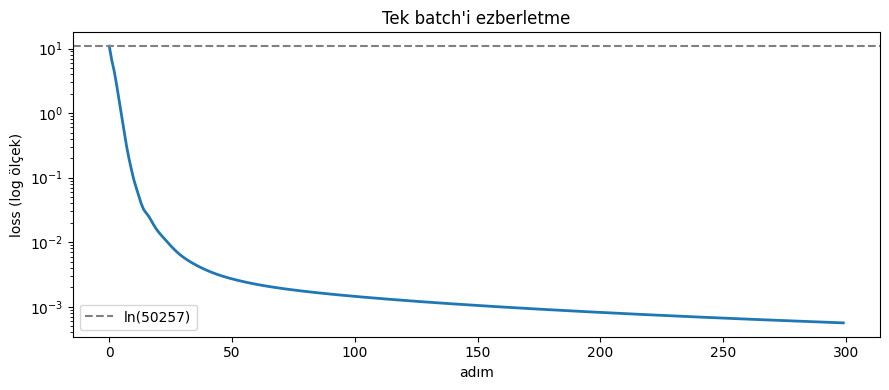

In [17]:
secili = sorted({0, 10, 25, 50, 100, 200, EZBER_ADIM - 1} & set(range(EZBER_ADIM)))
display(pd.DataFrame({"Adım": secili, "Loss": [f"{gecmis[a]:.6f}" for a in secili]}).style.hide(axis="index"))

fig, eksen = plt.subplots(figsize=(9, 4))
eksen.plot(gecmis, linewidth=2)
eksen.axhline(beklenen, color="gray", linestyle="--", label="ln(50257)")
eksen.set_yscale("log")
eksen.set_xlabel("adım")
eksen.set_ylabel("loss (log ölçek)")
eksen.set_title("Tek batch'i ezberletme")
eksen.legend()
plt.tight_layout()
plt.show()

**Cevap: Tek batch'i ezberletme testi neden işe yarıyor?**

300 adımda loss 10.8742'den 0.0006'ya indi (25. adımda zaten 0.0088) ve aynı batch'te doğru tahmin oranı %100 oldu. Bu test "model iyi mi?" sorusunu değil, "eğitim hattı çalışıyor mu?" sorusunu cevaplıyor. 124 milyon parametreli bir model için 128 token'lık veri çok küçük, ezberlemesi kolay olmalı. Loss sıfıra inmiyorsa model öğrenemiyor demektir ve kodda hata var. Tipik sebepler: optimizer'a parametreler verilmemiş, `zero_grad` unutulmuş, hedefler yanlış kaydırılmış, şekiller uyuşmuyor ya da gradyan bir yerde kopuyor.

Testin sınırı da var. Genelleme hakkında hiçbir şey söylemiyor. Ayrıca modelin gelecekteki token'ları görmesi gibi hataları yakalamıyor: nedensel maske bozuksa model cevabı doğrudan okuyup yine sıfır loss'a ulaşır. Onu Görev 2'deki "logits Hugging Face ile aynı mı" testi yakalıyor, iki test birbirini tamamlıyor.
